# SVM-model voor stroke prediction

**Onderdeel:** Support Vector Machine (SVM)  
**Doel:** voorspellen of een patiënt een herseninfarct (`stroke = 1`) krijgt.  

In dit notebook wordt alleen het SVM-gedeelte uitgewerkt. De nadruk ligt op:
- preprocessing;
- omgaan met een imbalanced dataset;
- cross-validation;
- hyperparameter tuning;
- threshold tuning;
- evaluatie met F1-score en confusion matrix;
- het maken van een Kaggle-submissionbestand.

## Gebruik van Generatieve AI

Voor dit onderdeel is ChatGPT gebruikt als hulpmiddel bij het maken en toelichten van het SVM-model. De AI is gebruikt voor ondersteuning bij de uitleg van SVM, het structureren van de preprocessing-pipeline, hyperparameter tuning, cross-validation en het interpreteren van evaluatiematen zoals F1-score en confusion matrix. De code, resultaten en conclusies zijn door mij gecontroleerd en aangepast aan de gebruikte dataset.

Bron:
OpenAI. (2026). ChatGPT. Prompt: "Help mij met het maken en uitleggen van een SVM-model voor een stroke prediction opdracht." Geraadpleegd op 3 oktober 2026, van https://chatgpt.com/c/6acbb7b9-adf4-83ed-992a-6c96ad1edef9

## 1. Imports

De imports hieronder zijn mede gestructureerd met hulp van ChatGPT (OpenAI, 2026, prompt 2: SVM preprocessing en pipeline).

In [1]:
# GenAI-bron: OpenAI, 2026, prompt 2: SVM preprocessing en pipeline.
# ChatGPT hielp bij het structureren van de imports voor preprocessing,
# modeltraining, hyperparameter tuning en evaluatie.

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

## 2. Data inladen

De dataset bestaat uit een trainingsbestand met de targetkolom `stroke` en een testbestand zonder targetkolom. De kolom `id` wordt alleen gebruikt voor het submissionbestand en niet als voorspellende variabele.

In [2]:
# GenAI-bron: OpenAI, 2026, prompt 2: SVM preprocessing en pipeline.
# ChatGPT hielp bij het opzetten van een duidelijke datastructuur:
# train.csv voor trainen/valideren, test.csv voor Kaggle-voorspellingen.

train_path = "train.csv"
test_path = "test.csv"
sample_submission_path = "sample_submission.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission = pd.read_csv(sample_submission_path)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission = pd.read_csv(sample_submission_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
display(train_df.head())

Train shape: (33550, 22)
Test shape: (8388, 21)


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


## 3. Korte controle van de targetverdeling

De dataset is imbalanced: er zijn veel meer patiënten zonder stroke dan met stroke. Daardoor is accuracy minder geschikt als hoofdmetric. Een model kan namelijk een hoge accuracy halen door bijna altijd `0` te voorspellen. Daarom wordt vooral de **F1-score** gebruikt.

,aantal,percentage
stroke,,
0,33033,98.46
1,517,1.54


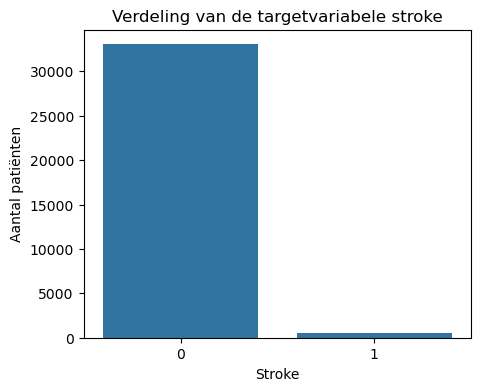

In [3]:
target_counts = train_df["stroke"].value_counts().sort_index()
target_percentages = train_df["stroke"].value_counts(normalize=True).sort_index() * 100

class_balance = pd.DataFrame({
    "aantal": target_counts,
    "percentage": target_percentages.round(2)
})

display(class_balance)

plt.figure(figsize=(5, 4))
sns.countplot(data=train_df, x="stroke")
plt.title("Verdeling van de targetvariabele stroke")
plt.xlabel("Stroke")
plt.ylabel("Aantal patiënten")
plt.show()

## 4. Theorie: hoe werkt een SVM?

Een Support Vector Machine probeert een scheidingslijn, vlak of hypervlak te vinden dat de klassen zo goed mogelijk van elkaar scheidt. Bij binaire classificatie zoekt SVM een grens tussen klasse `0` en klasse `1`. De punten die het dichtst bij deze grens liggen, heten **support vectors**. Deze punten bepalen voor een groot deel waar de grens komt te liggen (OpenAI, 2026, prompt 1: SVM theorie en begrippen).

Bij een lineaire SVM kan de beslisfunctie worden geschreven als:

$$
f(x) = w^T x + b
$$

Daarbij is:
- $$x$$ de invoer met kenmerken van een patiënt;
- $$w$$ de vector met gewichten;
- $$b$$ de bias/intercept;
- $$f(x)$$ de score waarmee wordt bepaald aan welke kant van de grens een patiënt valt.

De hyperparameter `C` bepaalt hoe streng het model fouten bestraft:
- lage `C`: meer regularisatie, eenvoudiger model, minder kans op overfitting;
- hoge `C`: minder regularisatie, model probeert trainingsdata beter te classificeren, maar kan sneller overfitten.

SVM kan ook met kernels werken, zoals een RBF-kernel. Een kernel maakt het mogelijk om niet-lineaire patronen te leren. In dit notebook is gekozen voor een **lineaire SVM** via `LinearSVC`, omdat de dataset al veel dummyvariabelen bevat en een lineair model sneller en beter uitlegbaar is.

*Margin*
De margin is de afstand tussen het hypervlak en de dichtstbijzijnde punten van beide klassen (de support vectors). SVM kiest het hypervlak met de grootste margin, omdat zo'n grens het beste generaliseert naar nieuwe patiënten. Bij een *hard margin* mag geen enkel punt aan de verkeerde kant liggen; dat werkt alleen als de klassen perfect te scheiden zijn. Onze data is dat niet, dus gebruiken we een *soft margin*: sommige punten mogen binnen de margin of aan de verkeerde kant liggen, tegen een straf. Hoe zwaar die straf is, bepaalt C.

*Kernel-trick*
Als de klassen niet met een rechte grens te scheiden zijn, kan een kernel helpen. Een kernel berekent de overeenkomst tussen twee patiënten alsof de data naar een ruimte met meer dimensies is omgezet, zonder die omzetting echt uit te rekenen. In die ruimte kan een rechte grens wel werken; terug in de oorspronkelijke ruimte is die grens gebogen. Veelgebruikte kernels zijn:
- linear: geen omzetting, een rechte grens;
- poly: een polynoom van een gekozen graad;
- rbf: de radial basis function, die de overeenkomst laat afnemen met de afstand tussen twee patiënten.

*Hyperparameters*
- C: de straf voor fouten. Een kleine C geeft een brede margin met meer fouten (meer regularisatie); een grote C een smalle margin die de trainingsdata nauwkeuriger volgt (risico op overfitting).
- kernel: de vorm van de grens (zie hierboven).
- gamma (bij rbf en poly): hoe ver de invloed van één punt reikt. Een grote gamma maakt de grens erg grillig (overfitting), een kleine gamma maakt hem glad.
- class_weight: met "balanced" tellen fouten bij de kleine klasse zwaarder mee (zie 6.1).

*Voor- en nadelen*
- Voordelen: werkt goed met veel features; de grote margin beperkt overfitting; met een kernel kan het model ook niet-lineaire grenzen leren.
- Nadelen: traag bij veel waarnemingen (een SVM met rbf-kernel op ruim 33.000 patiënten duurt lang, daarom gebruiken we LinearSVC); gevoelig voor de schaal van de features, dus standaardisatie is nodig; geeft standaard geen kansen, waardoor calibratie nodig is voor threshold tuning; moeilijk uit te leggen aan een arts.

## 5. Features en target scheiden

De target is `stroke`. De kolom `id` wordt verwijderd uit de features, omdat dit een identificatienummer is en geen medisch of demografisch kenmerk.

In [4]:
# GenAI-bron: OpenAI, 2026, prompt 2: SVM preprocessing en pipeline.
# ChatGPT hielp bij het splitsen van features en target en het vermijden
# van datalekken door 'id' niet als feature te gebruiken.

target_column = "stroke"
id_column = "id"

X = train_df.drop(columns=[id_column, target_column])
y = train_df[target_column].astype(int)

X_test = test_df.drop(columns=[id_column])

print("Aantal features:", X.shape[1])
print("Features:", list(X.columns))

Aantal features: 20
Features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


## 6. Train-validatiesplit

De data wordt opgesplitst in een trainingsset en validatieset. Door `stratify=y` te gebruiken blijft de verhouding tussen `stroke = 0` en `stroke = 1` ongeveer gelijk in beide sets.

In [5]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape)
print("Validatie:", X_valid.shape)
print("Stroke percentage train:", round(y_train.mean() * 100, 2))
print("Stroke percentage validatie:", round(y_valid.mean() * 100, 2))

Train: (26840, 20)
Validatie: (6710, 20)
Stroke percentage train: 1.54
Stroke percentage validatie: 1.54


## 7. Preprocessing en SVM-pipeline

SVM is gevoelig voor schaalverschillen tussen variabelen. Daarom worden de features gestandaardiseerd met `StandardScaler`. Missende waarden worden opgevuld met de mediaan. De dataset bevat vooral numerieke en dummyvariabelen, waardoor deze aanpak passend is.

Voor de imbalanced dataset wordt `class_weight="balanced"` gebruikt. Hierdoor krijgt de minderheidsklasse `stroke = 1` meer gewicht tijdens het trainen (OpenAI, 2026, prompt 3: SVM tuning met class imbalance).

In [6]:
# GenAI-bron: OpenAI, 2026, prompt 3: SVM tuning met class imbalance.
# ChatGPT hielp bij het combineren van SimpleImputer, StandardScaler en
# LinearSVC in één Pipeline en bij het gebruik van class_weight='balanced'.

svm_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "svm",
            LinearSVC(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                max_iter=10000,
                dual=False,
            ),
        ),
    ]
)

## 8. Cross-validation en hyperparameter tuning

Met `GridSearchCV` wordt gezocht naar de beste waarde voor `C`. De gekozen score is F1, omdat de competitie ook op F1-score beoordeelt en omdat F1 beter past bij een imbalanced classificatieprobleem dan accuracy.

In [7]:
# GenAI-bron: OpenAI, 2026, prompt 3: SVM tuning met class imbalance.
# ChatGPT hielp bij het opzetten van StratifiedKFold en GridSearchCV
# met scoring='f1' voor deze imbalanced dataset.

param_grid = {
    "svm__C": [0.01, 0.05, 0.1, 0.5, 1, 5]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE,
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

grid_search.fit(X_train, y_train)

print("Beste parameters:", grid_search.best_params_)
print("Beste gemiddelde F1-score tijdens CV:", round(grid_search.best_score_, 4))

cv_results = pd.DataFrame(grid_search.cv_results_)
display(
    cv_results[
        ["param_svm__C", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
)

Beste parameters: {'svm__C': 1}
Beste gemiddelde F1-score tijdens CV: 0.0885


,param_svm__C,mean_test_score,std_test_score,rank_test_score
5,5.00,0.088476,0.002134,1
4,1.00,0.088476,0.002134,1
3,0.50,0.088465,0.002132,3
2,0.10,0.088442,0.002106,4
1,0.05,0.088430,0.002105,5
0,0.01,0.088244,0.002115,6


## 9. Calibratie en threshold tuning

Een standaard classifier gebruikt vaak threshold `0.5`. Bij een imbalanced dataset is dat niet altijd optimaal. Daarom wordt het SVM-model eerst gekalibreerd, zodat we waarschijnlijkheidsscores kunnen gebruiken. Daarna testen we meerdere thresholds en kiezen we de threshold met de hoogste F1-score op de validatieset (OpenAI, 2026, prompt 4: threshold tuning en evaluatie).

Beste threshold: 0.056
Beste F1-score bij deze threshold: 0.1345


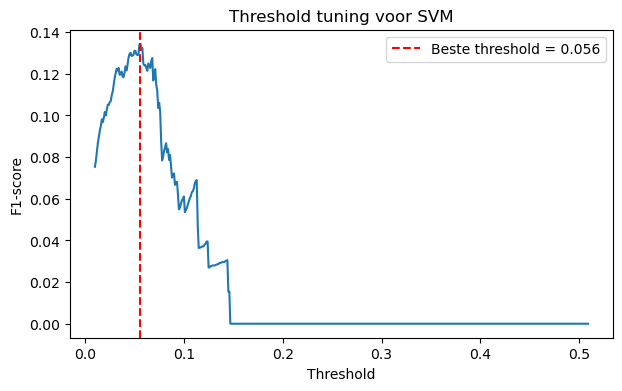

In [8]:
# GenAI-bron: OpenAI, 2026, prompt 4: threshold tuning en evaluatie.
# ChatGPT hielp bij de opzet van CalibratedClassifierCV en bij het zoeken
# naar de threshold die de hoogste validatie-F1-score oplevert.

calibrated_svm = CalibratedClassifierCV(
    estimator=grid_search.best_estimator_,
    method="sigmoid",
    cv=3,
)

calibrated_svm.fit(X_train, y_train)

valid_proba = calibrated_svm.predict_proba(X_valid)[:, 1]

thresholds = np.arange(0.01, 0.51, 0.001)
f1_scores = []

for threshold in thresholds:
    valid_pred_threshold = (valid_proba >= threshold).astype(int)
    score = f1_score(y_valid, valid_pred_threshold, zero_division=0)
    f1_scores.append(score)

best_index = int(np.argmax(f1_scores))
best_threshold = float(thresholds[best_index])
best_threshold_f1 = float(f1_scores[best_index])

print("Beste threshold:", round(best_threshold, 3))
print("Beste F1-score bij deze threshold:", round(best_threshold_f1, 4))

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_scores)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Beste threshold = {best_threshold:.3f}")
plt.title("Threshold tuning voor SVM")
plt.xlabel("Threshold")
plt.ylabel("F1-score")
plt.legend()
plt.show()

## 10. Evaluatie op de validatieset

Hier wordt het model geëvalueerd met de beste threshold. De confusion matrix laat zien hoeveel patiënten goed en fout zijn geclassificeerd. Vooral recall en F1-score zijn belangrijk, omdat we zoveel mogelijk strokegevallen willen herkennen zonder de precision volledig te verliezen.

In [9]:
# GenAI-bron: OpenAI, 2026, prompt 4: threshold tuning en evaluatie.
# ChatGPT hielp bij het samenbrengen van F1-score, precision, recall,
# accuracy, ROC-AUC, PR-AUC en de confusion matrix.

valid_pred = (valid_proba >= best_threshold).astype(int)

valid_f1 = f1_score(y_valid, valid_pred, zero_division=0)
valid_precision = precision_score(y_valid, valid_pred, zero_division=0)
valid_recall = recall_score(y_valid, valid_pred, zero_division=0)
valid_accuracy = accuracy_score(y_valid, valid_pred)
valid_roc_auc = roc_auc_score(y_valid, valid_proba)
valid_pr_auc = average_precision_score(y_valid, valid_proba)

print("F1-score:", round(valid_f1, 4))
print("Precision:", round(valid_precision, 4))
print("Recall:", round(valid_recall, 4))
print("Accuracy:", round(valid_accuracy, 4))
print("ROC-AUC:", round(valid_roc_auc, 4))
print("PR-AUC:", round(valid_pr_auc, 4))

print("\nClassification report:")
print(classification_report(y_valid, valid_pred, zero_division=0))

F1-score: 0.1345
Precision: 0.0813
Recall: 0.3883
Accuracy: 0.9232
ROC-AUC: 0.8547
PR-AUC: 0.0626

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      6607
           1       0.08      0.39      0.13       103

    accuracy                           0.92      6710
   macro avg       0.54      0.66      0.55      6710
weighted avg       0.98      0.92      0.95      6710



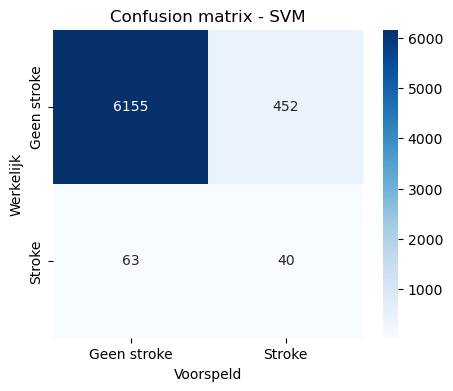

True negatives: 6155
False positives: 452
False negatives: 63
True positives: 40


In [10]:
cm = confusion_matrix(y_valid, valid_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Geen stroke", "Stroke"],
    yticklabels=["Geen stroke", "Stroke"],
)
plt.title("Confusion matrix - SVM")
plt.xlabel("Voorspeld")
plt.ylabel("Werkelijk")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

## 11. Precision-recall curve

De precision-recall curve is nuttig bij imbalanced datasets, omdat deze laat zien hoe precision en recall veranderen bij verschillende thresholds.

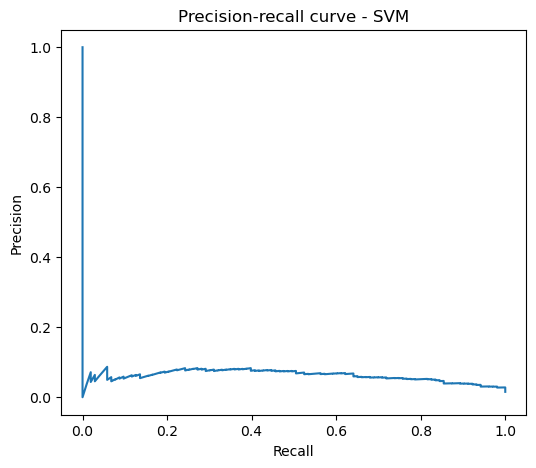

In [11]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_valid,
    valid_proba,
)

plt.figure(figsize=(6, 5))
plt.plot(recall_values, precision_values)
plt.title("Precision-recall curve - SVM")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

## 12. Resultaten opslaan

De belangrijkste resultaten worden opgeslagen in een apart CSV-bestand, zodat het SVM-model makkelijk kan worden vergeleken met andere modellen uit de groepsopdracht.

In [13]:
scores_df = pd.DataFrame(
    [
        {
            "model": "LinearSVM_class_weight_balanced_calibrated",
            "best_C": grid_search.best_params_["svm__C"],
            "cv_f1": grid_search.best_score_,
            "best_threshold": best_threshold,
            "valid_f1": valid_f1,
            "valid_precision": valid_precision,
            "valid_recall": valid_recall,
            "valid_accuracy": valid_accuracy,
            "valid_roc_auc": valid_roc_auc,
            "valid_pr_auc": valid_pr_auc,
        }
    ]
)

scores_path = "svm_scores_v2.csv"
scores_df.to_csv(scores_path, index=False)

display(scores_df)
print("Scores opgeslagen als:", scores_path)

,model,best_C,cv_f1,best_threshold,valid_f1,valid_precision,valid_recall,valid_accuracy,valid_roc_auc,valid_pr_auc
0,LinearSVM_class_weight_balanced_calibrated,1,0.088476,0.056,0.134454,0.081301,0.38835,0.923249,0.854673,0.062619


Scores opgeslagen als: svm_scores_v2.csv


## 13. Kaggle-submission maken

Voor Kaggle wordt het beste SVM-model opnieuw gebruikt om voorspellingen te maken voor `test.csv`. De voorspellingen worden opgeslagen met de kolommen `id` en `stroke` (OpenAI, 2026, prompt 5: Kaggle-submission maken).

In [16]:
# GenAI-bron: OpenAI, 2026, prompt 5: Kaggle-submission maken.
# ChatGPT hielp bij het maken van de juiste outputstructuur met kolommen
# 'id' en 'stroke' voor upload naar Kaggle.

best_c = grid_search.best_params_["svm__C"]

final_svm_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        (
            "svm",
            LinearSVC(
                C=best_c,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                max_iter=10000,
                dual=False,
            ),
        ),
    ]
)

final_svm_model = CalibratedClassifierCV(
    estimator=final_svm_pipeline,
    method="sigmoid",
    cv=3,
)

final_svm_model.fit(X, y)

test_proba = final_svm_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

submission = pd.DataFrame(
    {
        "id": test_df["id"],
        "stroke": test_pred,
    }
)

submission_path = "submission_svm_v2.csv"
submission.to_csv(submission_path, index=False)

display(submission.head())
print("Submission opgeslagen als:", submission_path)
print("Verdeling voorspellingen:")
print(submission["stroke"].value_counts())

,id,stroke
0,32840,0
1,45158,0
2,56105,0
3,3112,0
4,35224,0


Submission opgeslagen als: submission_svm_v2.csv
Verdeling voorspellingen:
stroke
0    7756
1     632
Name: count, dtype: int64


## 14. Conclusie SVM-model

Het SVM-model is getraind met `class_weight="balanced"` om rekening te houden met de scheve verdeling in de dataset. Daarna is met cross-validation gezocht naar de beste waarde voor `C`. Omdat de dataset imbalanced is, is niet alleen gekeken naar accuracy, maar vooral naar F1-score, precision en recall.

De gekozen threshold is lager dan 0.5, omdat het model anders waarschijnlijk te weinig strokegevallen voorspelt. Dit verhoogt de recall, maar zorgt ook voor meer false positives. Voor een medische toepassing is dit belangrijk: het missen van risicopatiënten kan ernstige gevolgen hebben, maar te veel fout-positieve voorspellingen kunnen ook leiden tot onnodige vervolgonderzoeken. Daarom moet een model als dit altijd worden gebruikt als ondersteuning en niet als vervanging van een arts.

## 15. Referentielijst

OpenAI. (2026). ChatGPT. Prompt 1: *SVM theorie en begrippen*. Gebruikt voor uitleg over Support Vector Machine, hyperplane, support vectors, margin, kernel trick en regularisatie. Geraadpleegd op 7 oktober 2026, van [vul hier de deelbare ChatGPT-link in].

OpenAI. (2026). ChatGPT. Prompt 2: *SVM preprocessing en pipeline*. Gebruikt voor ondersteuning bij imports, data inladen, features/target splitsen en preprocessing. Geraadpleegd op 7 oktober 2026, van [vul hier de deelbare ChatGPT-link in].

OpenAI. (2026). ChatGPT. Prompt 3: *SVM tuning met class imbalance*. Gebruikt voor ondersteuning bij `class_weight="balanced"`, `StratifiedKFold` en `GridSearchCV`. Geraadpleegd op 7 oktober 2026, van [vul hier de deelbare ChatGPT-link in].

OpenAI. (2026). ChatGPT. Prompt 4: *Threshold tuning en evaluatie*. Gebruikt voor ondersteuning bij calibratie, threshold tuning, F1-score, precision, recall, confusion matrix, ROC-AUC en PR-AUC. Geraadpleegd op 7 oktober 2026, van [vul hier de deelbare ChatGPT-link in].

OpenAI. (2026). ChatGPT. Prompt 5: *Kaggle-submission maken*. Gebruikt voor ondersteuning bij het maken van het submissionbestand met `id` en `stroke`. Geraadpleegd op 7 oktober 2026, van [vul hier de deelbare ChatGPT-link in].

## Bijlage: exacte prompts die gebruikt/gegeven kunnen worden

**Prompt 1: SVM theorie en begrippen**  
Leg in het Nederlands op hbo-studentniveau uit hoe een Support Vector Machine werkt voor binaire classificatie. Gebruik de context van een stroke prediction opdracht met target `stroke`. Leg de begrippen hyperplane, support vectors, margin, kernel trick, lineaire SVM en regularisatie met parameter `C` uit. Voeg ook de formule $$f(x) = w^T x + b$$ toe en leg uit waarom F1-score belangrijk is bij een imbalanced dataset.

**Prompt 2: SVM preprocessing en pipeline**  
Maak Python-code voor een Jupyter Notebook waarin `train.csv`, `test.csv` en `sample_submission.csv` worden ingeladen vanaf vaste bestandspaden. De targetkolom heet `stroke` en de kolom `id` mag niet als feature worden gebruikt. Splits de data in `X`, `y` en `X_test`. Maak een train-validatiesplit met `train_test_split`, `test_size=0.20`, `stratify=y` en `random_state=42`. Gebruik `SimpleImputer(strategy="median")`, `StandardScaler()` en `LinearSVC` in een sklearn `Pipeline`.

**Prompt 3: SVM tuning met class imbalance**  
Breid de SVM-pipeline uit met `LinearSVC(class_weight="balanced", random_state=42, max_iter=10000, dual=False)`. Gebruik `GridSearchCV` met `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`. Tune de parameter `svm__C` met de waarden `[0.01, 0.05, 0.1, 0.5, 1, 5]`. Gebruik `scoring="f1"`, `n_jobs=-1` en print de beste parameters en beste gemiddelde F1-score.

**Prompt 4: Threshold tuning en evaluatie**  
Maak Python-code om het beste SVM-model uit `GridSearchCV` te kalibreren met `CalibratedClassifierCV(method="sigmoid", cv=3)`. Bereken voorspelde kansen op de validatieset. Test thresholds van 0.01 tot en met 0.50 met stappen van 0.001. Kies de threshold met de hoogste F1-score. Evalueer daarna met F1-score, precision, recall, accuracy, ROC-AUC, PR-AUC, classification report en confusion matrix. Maak ook een plot van threshold versus F1-score en een precision-recall curve.

**Prompt 5: Kaggle-submission maken**  
Maak Python-code om het definitieve SVM-model opnieuw te trainen op de volledige trainingsdata met de beste `C`. Kalibreer het model met `CalibratedClassifierCV(method="sigmoid", cv=3)`. Maak voorspellingen voor `test.csv` met de beste threshold uit de validatieset. Maak een dataframe met kolommen `id` en `stroke` en sla dit op als `/mnt/data/submission_svm_v2.csv`. Sla de validatiescores op als `/mnt/data/svm_scores_v2.csv`.